# 🛰️ LoveDA + U-Net++ — Stage 1 Only

**Goal:** Build a normal U-Net++ baseline for satellite-image semantic segmentation.

`LoveDA → EDA → Image + Mask → Class Distribution → U-Net++ → Layer Analysis → Cross-Entropy → 10 Epochs → Dice + IoU → Best Model → New Satellite Image Prediction`

🚫 **Stage 2 is NOT included:** no calibration, class weights, combined loss, hypothesis testing, or manual epoch guidance.

**Run one cell at a time in Google Colab.**


## Dataset

We use the **LoveDA remote-sensing semantic-segmentation dataset**.

The model learns from:

`Satellite image + ground-truth mask → pixel-wise segmentation`

The raw masks contain a no-data label plus seven land-cover classes.


# CELL 1 — Install packages

In [1]:
!pip -q install segmentation-models-pytorch kagglehub scikit-learn pillow tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 7.6 MB/s eta 0:00:00


# CELL 2 — Imports

In [2]:
import os
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import segmentation_models_pytorch as smp

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


# CELL 3 — Reproducibility and device

In [3]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", DEVICE)


Using: cuda


# CELL 4 — Download LoveDA from Kaggle

If this Kaggle slug is unavailable, replace `DATASET_HANDLE` with the LoveDA dataset slug you selected on Kaggle.

In [4]:
import kagglehub

DATASET_HANDLE = "alienxc137/loveda-satellite-images-semantic-segmentation"

LOVE_DA_ROOT = Path(kagglehub.dataset_download(DATASET_HANDLE))
print("LoveDA downloaded to:", LOVE_DA_ROOT)


100%|██████████| 8.92G/8.92G [09:37<00:00, 16.6MB/s]

Extracting files...


LoveDA downloaded to: /root/.cache/kagglehub/datasets/alienxc137/loveda-satellite-images-semantic-segmentation/versions/1


# CELL 5 — Inspect dataset folders

In [5]:
for p in sorted(LOVE_DA_ROOT.rglob("*")):
    if p.is_dir():
        rel = p.relative_to(LOVE_DA_ROOT)
        if len(rel.parts) <= 4:
            print("  " * len(rel.parts) + "📁 " + p.name)


  📁 Test
    📁 Test
      📁 Rural
        📁 images_png
      📁 Urban
        📁 images_png
  📁 Train
    📁 Train
      📁 Rural
        📁 images_png
        📁 masks_png
      📁 Urban
        📁 images_png
        📁 masks_png
  📁 Val
    📁 Val
      📁 Rural
        📁 images_png
        📁 masks_png
      📁 Urban
        📁 images_png
        📁 masks_png


# CELL 6 — Find image and mask folders

In [6]:
EXTENSIONS = {".png", ".jpg", ".jpeg", ".tif", ".tiff"}

def files_in(folder):
    return [p for p in folder.rglob("*")
            if p.is_file() and p.suffix.lower() in EXTENSIONS]

image_candidates = []
mask_candidates = []

for p in LOVE_DA_ROOT.rglob("*"):
    if not p.is_dir():
        continue
    name = p.name.lower()

    if any(x in name for x in ["images_png", "images", "image"]):
        image_candidates.append(p)

    if any(x in name for x in ["masks_png", "masks", "mask", "label", "ann"]):
        mask_candidates.append(p)

print("IMAGE candidates:")
for p in image_candidates:
    print(p, "->", len(files_in(p)))

print("\nMASK candidates:")
for p in mask_candidates:
    print(p, "->", len(files_in(p)))


IMAGE candidates:
/root/.cache/kagglehub/datasets/alienxc137/loveda-satellite-images-semantic-segmentation/versions/1/Val/Val/Rural/images_png -> 992
/root/.cache/kagglehub/datasets/alienxc137/loveda-satellite-images-semantic-segmentation/versions/1/Val/Val/Urban/images_png -> 677
/root/.cache/kagglehub/datasets/alienxc137/loveda-satellite-images-semantic-segmentation/versions/1/Train/Train/Rural/images_png -> 1366
/root/.cache/kagglehub/datasets/alienxc137/loveda-satellite-images-semantic-segmentation/versions/1/Train/Train/Urban/images_png -> 1156
/root/.cache/kagglehub/datasets/alienxc137/loveda-satellite-images-semantic-segmentation/versions/1/Test/Test/Rural/images_png -> 976
/root/.cache/kagglehub/datasets/alienxc137/loveda-satellite-images-semantic-segmentation/versions/1/Test/Test/Urban/images_png -> 820

MASK candidates:
/root/.cache/kagglehub/datasets/alienxc137/loveda-satellite-images-semantic-segmentation/versions/1/Val/Val/Rural/masks_png -> 992
/root/.cache/kagglehub/data

# CELL 7 — Select image and mask directories

In [7]:
image_candidates = sorted(image_candidates, key=lambda p: len(files_in(p)), reverse=True)
mask_candidates = sorted(mask_candidates, key=lambda p: len(files_in(p)), reverse=True)

IMAGE_DIR = image_candidates[0]
MASK_DIR = mask_candidates[0]

print("IMAGE_DIR:", IMAGE_DIR)
print("MASK_DIR :", MASK_DIR)
print("Images   :", len(files_in(IMAGE_DIR)))
print("Masks    :", len(files_in(MASK_DIR)))


IMAGE_DIR: /root/.cache/kagglehub/datasets/alienxc137/loveda-satellite-images-semantic-segmentation/versions/1/Train/Train/Rural/images_png
MASK_DIR : /root/.cache/kagglehub/datasets/alienxc137/loveda-satellite-images-semantic-segmentation/versions/1/Train/Train/Rural/masks_png
Images   : 1366
Masks    : 1366


# CELL 8 — Match images with masks

In [8]:
image_files = files_in(IMAGE_DIR)
mask_files = files_in(MASK_DIR)

def stem_key(path):
    return path.stem.lower().replace("_mask", "").replace("_label", "")

mask_map = {stem_key(p): p for p in mask_files}

pairs = []
for image_path in image_files:
    key = stem_key(image_path)
    if key in mask_map:
        pairs.append((image_path, mask_map[key]))

print("Images:", len(image_files))
print("Masks :", len(mask_files))
print("Matched pairs:", len(pairs))

assert pairs, "No image-mask pairs found. Check Cell 7."


Images: 1366
Masks : 1366
Matched pairs: 1366


# CELL 9 — EDA: inspect one sample

In [9]:
sample_image_path, sample_mask_path = pairs[0]

sample_image = Image.open(sample_image_path).convert("RGB")
sample_mask = Image.open(sample_mask_path)

print("Image size:", sample_image.size)
print("Image mode:", sample_image.mode)
print("Mask size :", sample_mask.size)
print("Mask mode :", sample_mask.mode)
print("Raw mask values:", np.unique(np.asarray(sample_mask))[:30])


Image size: (1024, 1024)
Image mode: RGB
Mask size : (1024, 1024)
Mask mode : L
Raw mask values: [1 2 3 4 6 7]


# CELL 10 — Show satellite image

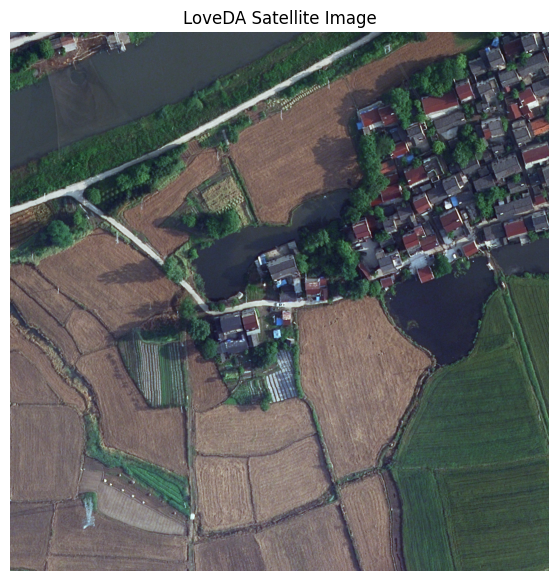

In [10]:
plt.figure(figsize=(7, 7))
plt.imshow(sample_image)
plt.title("LoveDA Satellite Image")
plt.axis("off")
plt.show()


# CELL 11 — Show ground-truth mask

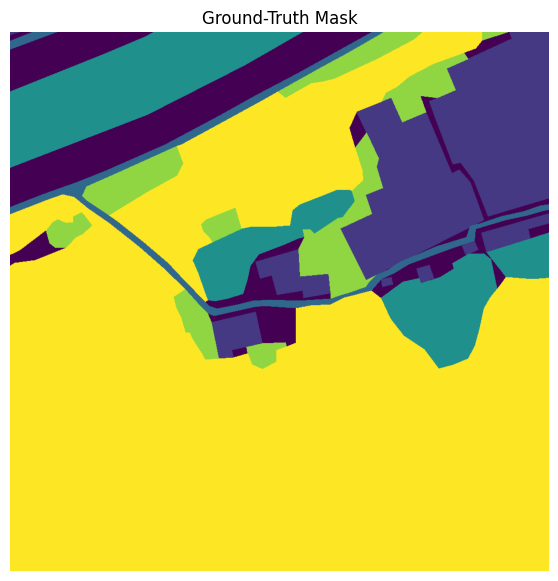

In [11]:
plt.figure(figsize=(7, 7))
plt.imshow(sample_mask)
plt.title("Ground-Truth Mask")
plt.axis("off")
plt.show()


# CELL 12 — Image + mask side-by-side

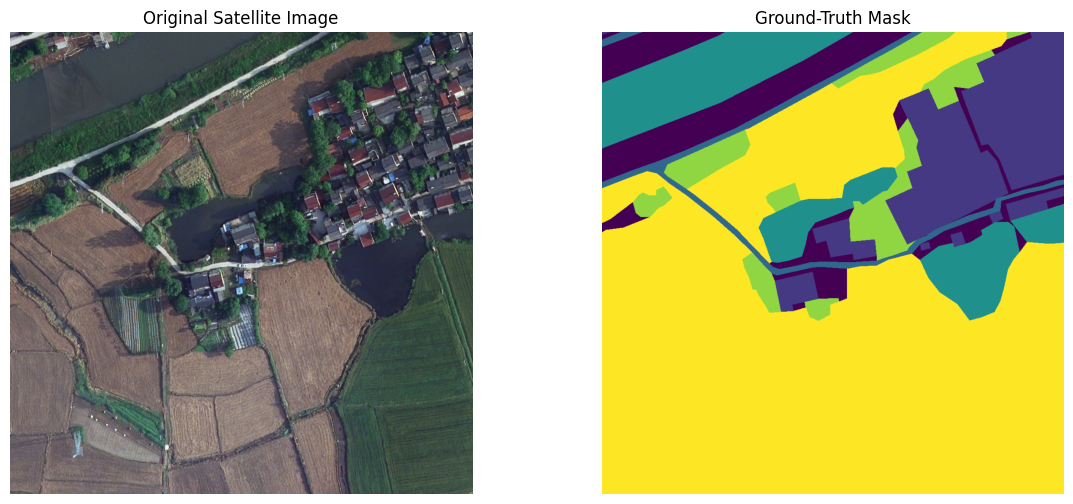

In [12]:
plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
plt.imshow(sample_image)
plt.title("Original Satellite Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(sample_mask)
plt.title("Ground-Truth Mask")
plt.axis("off")
plt.show()


# CELL 13 — Define LoveDA classes

In [13]:
CLASS_NAMES = [
    "Background",
    "Building",
    "Road",
    "Water",
    "Barren",
    "Forest",
    "Agriculture"
]

NUM_CLASSES = len(CLASS_NAMES)
IGNORE_INDEX = 255

for i, name in enumerate(CLASS_NAMES):
    print(i, "→", name)


0 → Background
1 → Building
2 → Road
3 → Water
4 → Barren
5 → Forest
6 → Agriculture


# CELL 14 — Convert raw masks

Raw `0` becomes an ignored pixel (`255`); raw `1..7` become training IDs `0..6`.

In [14]:
def convert_mask(mask):
    raw = np.asarray(mask).astype(np.int64)

    converted = np.full(raw.shape, IGNORE_INDEX, dtype=np.int64)
    valid = (raw >= 1) & (raw <= 7)
    converted[valid] = raw[valid] - 1

    return converted

converted_sample = convert_mask(sample_mask)

print("Raw values:", np.unique(np.asarray(sample_mask)))
print("Training values:", np.unique(converted_sample))


Raw values: [1 2 3 4 6 7]
Training values: [0 1 2 3 5 6]


# CELL 15 — Class distribution

EDA only. We observe class imbalance here; we do **not** apply class weights yet.

In [15]:
pixel_counts = np.zeros(NUM_CLASSES, dtype=np.int64)

for _, mask_path in tqdm(pairs, desc="Counting pixels"):
    m = convert_mask(Image.open(mask_path))
    valid = m != IGNORE_INDEX
    pixel_counts += np.bincount(m[valid].ravel(), minlength=NUM_CLASSES)

distribution = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Pixels": pixel_counts
})
distribution["Percentage"] = distribution["Pixels"] / distribution["Pixels"].sum() * 100

display(distribution)


Counting pixels:   0%|          | 0/1366 [00:00<?, ?it/s]

,Class,Pixels,Percentage
0,Background,351704076,25.282114
1,Building,36891628,2.651941
2,Road,27053972,1.944764
3,Water,119674656,8.602767
4,Barren,45460577,3.267916
5,Forest,317735062,22.840264
6,Agriculture,492598197,35.410234


# CELL 16 — Class distribution graph

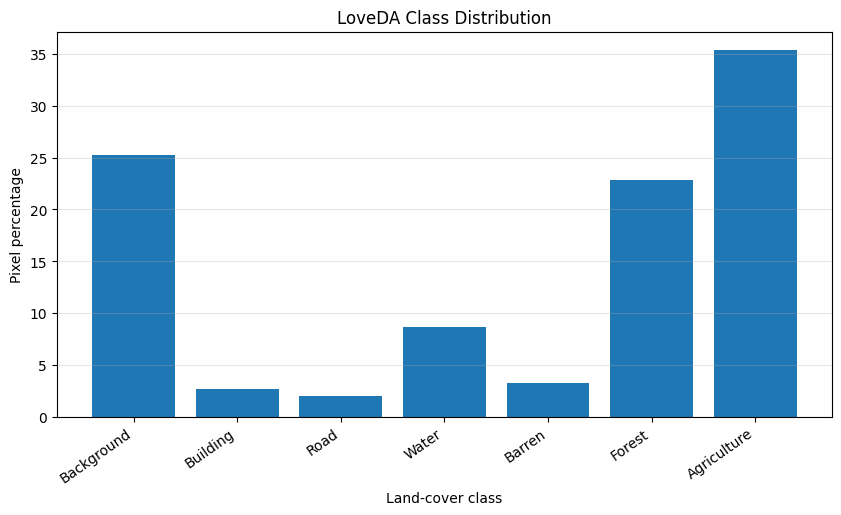

In [16]:
plt.figure(figsize=(10, 5))
plt.bar(distribution["Class"], distribution["Percentage"])
plt.xlabel("Land-cover class")
plt.ylabel("Pixel percentage")
plt.title("LoveDA Class Distribution")
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.show()


# CELL 17 — Train/validation split

In [17]:
from sklearn.model_selection import train_test_split

train_pairs, val_pairs = train_test_split(
    pairs,
    test_size=0.20,
    random_state=SEED,
    shuffle=True
)

print("Training pairs  :", len(train_pairs))
print("Validation pairs:", len(val_pairs))


Training pairs  : 1092
Validation pairs: 274


# CELL 18 — PyTorch Dataset

In [18]:
class LoveDADataset(Dataset):
    def __init__(self, pairs, image_size=256):
        self.pairs = pairs
        self.image_size = image_size

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        image_path, mask_path = self.pairs[idx]

        image = Image.open(image_path).convert("RGB")
        mask = Image.open(mask_path)

        image = image.resize(
            (self.image_size, self.image_size),
            Image.Resampling.BILINEAR
        )
        mask = mask.resize(
            (self.image_size, self.image_size),
            Image.Resampling.NEAREST
        )

        image = np.asarray(image).astype(np.float32) / 255.0
        mask = convert_mask(mask)

        image = torch.from_numpy(image).permute(2, 0, 1)
        mask = torch.from_numpy(mask.astype(np.int64))

        return image, mask


# CELL 19 — DataLoaders

In [19]:
IMAGE_SIZE = 256
BATCH_SIZE = 4
NUM_WORKERS = 2

train_dataset = LoveDADataset(train_pairs, IMAGE_SIZE)
val_dataset = LoveDADataset(val_pairs, IMAGE_SIZE)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

print("Train batches:", len(train_loader))
print("Val batches  :", len(val_loader))


Train batches: 273
Val batches  : 69


# CELL 20 — Check one batch

In [20]:
batch_images, batch_masks = next(iter(train_loader))

print("Images shape:", batch_images.shape)
print("Masks shape :", batch_masks.shape)
print("Mask values :", torch.unique(batch_masks))


Images shape: torch.Size([4, 3, 256, 256])
Masks shape : torch.Size([4, 256, 256])
Mask values : tensor([0, 1, 2, 3, 4, 5, 6])


# CELL 21 — Build normal U-Net++

In [21]:
model = smp.UnetPlusPlus(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=3,
    classes=NUM_CLASSES,
    activation=None
).to(DEVICE)

print("U-Net++ ready.")


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

U-Net++ ready.


# CELL 22 — Layer and parameter analysis

In [22]:
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Total parameters    : {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

print("\nMain components:")
print("Encoder          :", model.encoder.__class__.__name__)
print("Decoder          :", model.decoder.__class__.__name__)
print("Segmentation head:", model.segmentation_head.__class__.__name__)


Total parameters    : 26,079,479
Trainable parameters: 26,079,479

Main components:
Encoder          : ResNetEncoder
Decoder          : UnetPlusPlusDecoder
Segmentation head: SegmentationHead


# CELL 23 — Normal Cross-Entropy loss

In [23]:
criterion = nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4
)

print("Loss:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", 1e-4)


Loss: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.0001


# CELL 24 — Dice score

In [24]:
def dice_score(logits, target, num_classes):
    pred = torch.argmax(logits, dim=1)
    scores = []

    for cls in range(num_classes):
        valid = target != IGNORE_INDEX
        p = (pred == cls) & valid
        t = (target == cls) & valid

        intersection = (p & t).sum().float()
        denominator = p.sum().float() + t.sum().float()

        scores.append(
            (2 * intersection + 1e-7) /
            (denominator + 1e-7)
        )

    return torch.stack(scores).mean()


# CELL 25 — IoU score

In [25]:
def iou_score(logits, target, num_classes):
    pred = torch.argmax(logits, dim=1)
    scores = []

    for cls in range(num_classes):
        valid = target != IGNORE_INDEX
        p = (pred == cls) & valid
        t = (target == cls) & valid

        intersection = (p & t).sum().float()
        union = p.sum().float() + t.sum().float() - intersection

        scores.append(
            (intersection + 1e-7) /
            (union + 1e-7)
        )

    return torch.stack(scores).mean()


# CELL 26 — Train one epoch

In [26]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss = 0.0

    for images, masks in loader:
        images = images.to(DEVICE)
        masks = masks.to(DEVICE)

        optimizer.zero_grad()

        logits = model(images)
        loss = criterion(logits, masks)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(loader)


# CELL 27 — Validation

In [27]:
@torch.no_grad()
def validate(model, loader, criterion):
    model.eval()

    losses = []
    dices = []
    ious = []

    for images, masks in loader:
        images = images.to(DEVICE)
        masks = masks.to(DEVICE)

        logits = model(images)
        loss = criterion(logits, masks)

        losses.append(loss.item())
        dices.append(dice_score(logits, masks, NUM_CLASSES).item())
        ious.append(iou_score(logits, masks, NUM_CLASSES).item())

    return np.mean(losses), np.mean(dices), np.mean(ious)


# CELL 28 — Train U-Net++ for 10 epochs

The model with the highest validation Dice is saved as the Stage 1 best baseline.

In [28]:
EPOCHS = 10

history = []
best_dice = -1
best_epoch = 0

for epoch in range(1, EPOCHS + 1):

    train_loss = train_one_epoch(
        model, train_loader, criterion, optimizer
    )

    val_loss, dice, iou = validate(
        model, val_loader, criterion
    )

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "dice": dice,
        "iou": iou
    })

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train Loss={train_loss:.4f} | "
        f"Val Loss={val_loss:.4f} | "
        f"Dice={dice:.4f} | "
        f"IoU={iou:.4f}"
    )

    if dice > best_dice:
        best_dice = dice
        best_epoch = epoch

        torch.save(
            model.state_dict(),
            "LoveDA_UNetPlusPlus_Stage1_Best.pth"
        )

        print("  ⭐ Best Stage 1 model saved.")

print("\nBest epoch:", best_epoch)
print("Best validation Dice:", best_dice)


Epoch 01/10 | Train Loss=1.2404 | Val Loss=0.8279 | Dice=0.4942 | IoU=0.3860
  ⭐ Best Stage 1 model saved.
Epoch 02/10 | Train Loss=0.9406 | Val Loss=0.7381 | Dice=0.5129 | IoU=0.4028
  ⭐ Best Stage 1 model saved.
Epoch 03/10 | Train Loss=0.8594 | Val Loss=0.6916 | Dice=0.5726 | IoU=0.4572
  ⭐ Best Stage 1 model saved.
Epoch 04/10 | Train Loss=0.7498 | Val Loss=0.6847 | Dice=0.5864 | IoU=0.4637
  ⭐ Best Stage 1 model saved.
Epoch 05/10 | Train Loss=0.6784 | Val Loss=0.6932 | Dice=0.6091 | IoU=0.4839
  ⭐ Best Stage 1 model saved.
Epoch 06/10 | Train Loss=0.6430 | Val Loss=0.6777 | Dice=0.6166 | IoU=0.4899
  ⭐ Best Stage 1 model saved.
Epoch 07/10 | Train Loss=0.5643 | Val Loss=0.6066 | Dice=0.6254 | IoU=0.5055
  ⭐ Best Stage 1 model saved.
Epoch 08/10 | Train Loss=0.5229 | Val Loss=0.6103 | Dice=0.6359 | IoU=0.5140
  ⭐ Best Stage 1 model saved.
Epoch 09/10 | Train Loss=0.4626 | Val Loss=0.6175 | Dice=0.6376 | IoU=0.5135
  ⭐ Best Stage 1 model saved.
Epoch 10/10 | Train Loss=0.4530 | Val

# CELL 29 — Training results table

In [29]:
history_df = pd.DataFrame(history)
display(history_df)


,epoch,train_loss,val_loss,dice,iou
0,1,1.240441,0.827886,0.494191,0.385976
1,2,0.940568,0.738121,0.512948,0.402795
2,3,0.859355,0.691569,0.572607,0.457235
3,4,0.749760,0.684716,0.586381,0.463697
4,5,0.678406,0.693231,0.609111,0.483861
5,6,0.642953,0.677663,0.616591,0.489864
6,7,0.564258,0.606631,0.625378,0.505501
7,8,0.522930,0.610284,0.635937,0.513991
8,9,0.462558,0.617508,0.637597,0.513509
9,10,0.453017,0.645628,0.626672,0.503026


# CELL 30 — Loss graph

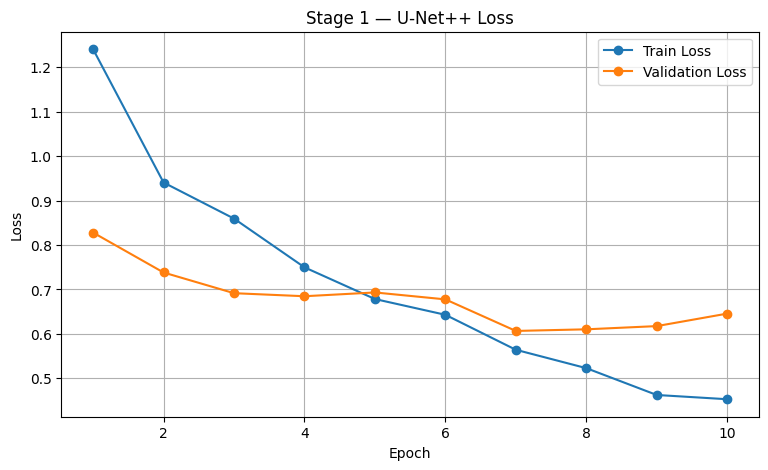

In [30]:
plt.figure(figsize=(9, 5))

plt.plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Train Loss")
plt.plot(history_df["epoch"], history_df["val_loss"], marker="o", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Stage 1 — U-Net++ Loss")
plt.legend()
plt.grid(True)
plt.show()


# CELL 31 — Dice and IoU graph

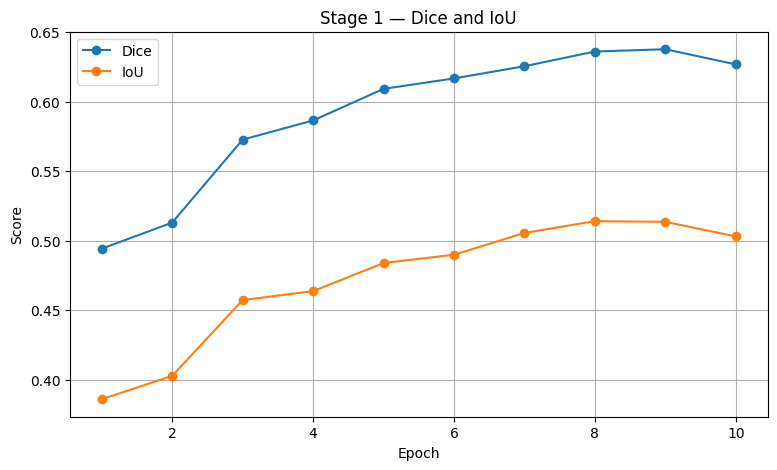

In [31]:
plt.figure(figsize=(9, 5))

plt.plot(history_df["epoch"], history_df["dice"], marker="o", label="Dice")
plt.plot(history_df["epoch"], history_df["iou"], marker="o", label="IoU")

plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("Stage 1 — Dice and IoU")
plt.legend()
plt.grid(True)
plt.show()


# CELL 32 — Load the best Stage 1 model

In [32]:
best_model = smp.UnetPlusPlus(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=3,
    classes=NUM_CLASSES,
    activation=None
).to(DEVICE)

best_model.load_state_dict(
    torch.load(
        "LoveDA_UNetPlusPlus_Stage1_Best.pth",
        map_location=DEVICE
    )
)

best_model.eval()

print("Best Stage 1 model loaded.")
print("Best epoch:", best_epoch)
print("Best Dice:", best_dice)


Best Stage 1 model loaded.
Best epoch: 9
Best Dice: 0.6375970754070558


# CELL 33 — Validation prediction

Shows `Original → Ground Truth → U-Net++ Prediction`.

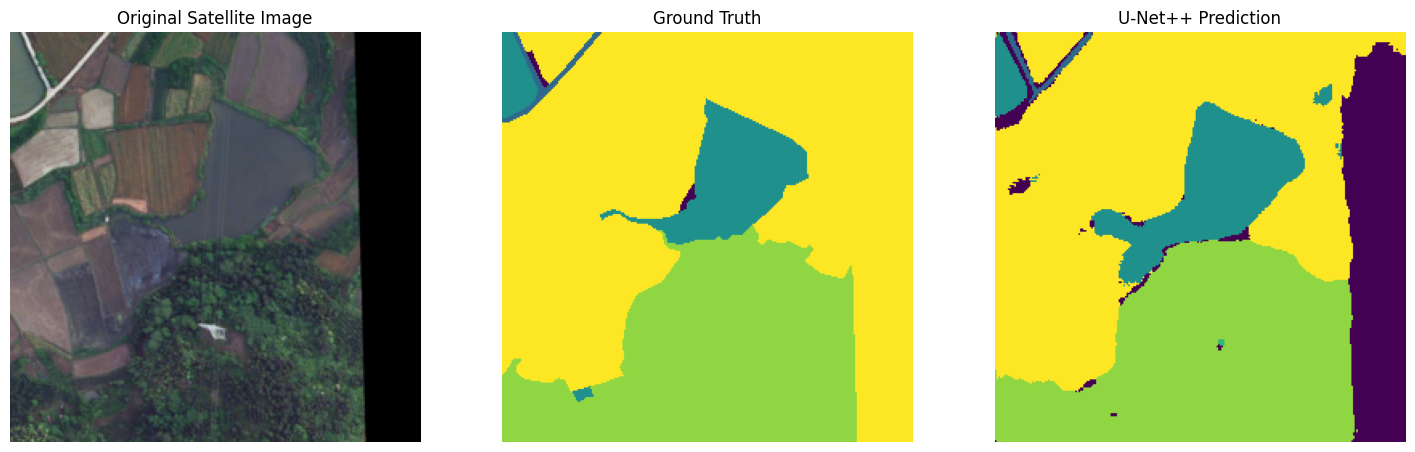

In [33]:
@torch.no_grad()
def predict_tensor(model, image_tensor):
    logits = model(image_tensor.unsqueeze(0).to(DEVICE))
    return torch.argmax(logits, dim=1)[0].cpu().numpy()

image_tensor, true_mask = val_dataset[0]
prediction = predict_tensor(best_model, image_tensor)

plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plt.imshow(image_tensor.permute(1, 2, 0))
plt.title("Original Satellite Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(true_mask, vmin=0, vmax=NUM_CLASSES-1)
plt.title("Ground Truth")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(prediction, vmin=0, vmax=NUM_CLASSES-1)
plt.title("U-Net++ Prediction")
plt.axis("off")

plt.show()


# CELL 34 — Predicted class distribution

,Class ID,Class,Predicted Pixels
0,0,Background,9477
1,2,Road,300
2,3,Water,6685
3,4,Barren,15
4,5,Forest,19421
5,6,Agriculture,29638


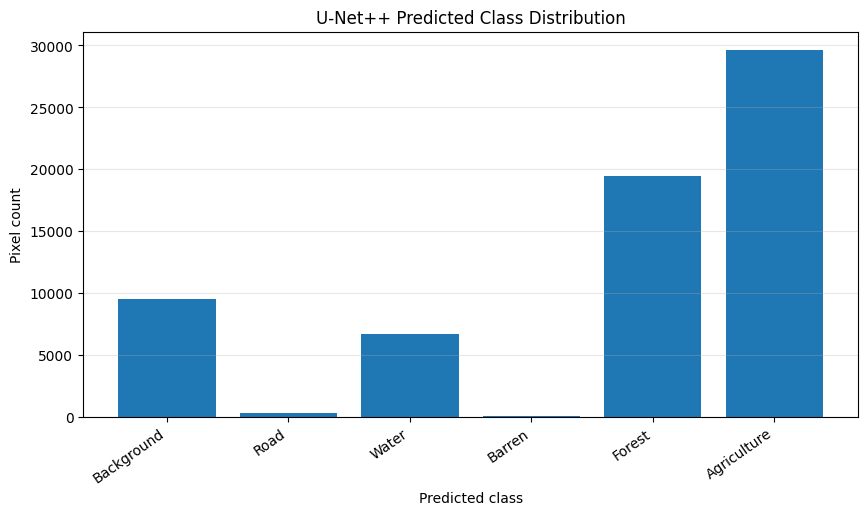

In [34]:
unique, counts = np.unique(prediction, return_counts=True)

pred_table = pd.DataFrame({
    "Class ID": unique,
    "Class": [CLASS_NAMES[i] for i in unique],
    "Predicted Pixels": counts
})

display(pred_table)

plt.figure(figsize=(10, 5))
plt.bar(pred_table["Class"], pred_table["Predicted Pixels"])
plt.xlabel("Predicted class")
plt.ylabel("Pixel count")
plt.title("U-Net++ Predicted Class Distribution")
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.show()


# CELL 35 — Upload a NEW satellite image

In [35]:
from google.colab import files

uploaded = files.upload()
NEW_IMAGE_PATH = next(iter(uploaded.keys()))

print("Uploaded:", NEW_IMAGE_PATH)


Saving Media.jpg to Media.jpg
Uploaded: Media.jpg


# CELL 36 — Predict the NEW satellite image

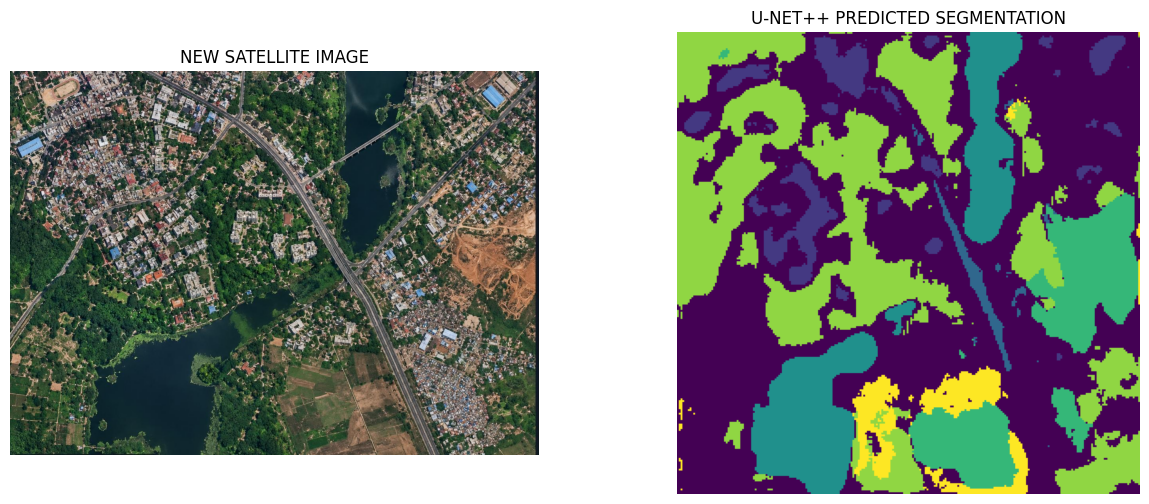

In [36]:
new_image = Image.open(NEW_IMAGE_PATH).convert("RGB")

resized = new_image.resize(
    (IMAGE_SIZE, IMAGE_SIZE),
    Image.Resampling.BILINEAR
)

arr = np.asarray(resized).astype(np.float32) / 255.0
new_tensor = torch.from_numpy(arr).permute(2, 0, 1)

new_prediction = predict_tensor(best_model, new_tensor)

plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
plt.imshow(new_image)
plt.title("NEW SATELLITE IMAGE")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(new_prediction, vmin=0, vmax=NUM_CLASSES-1)
plt.title("U-NET++ PREDICTED SEGMENTATION")
plt.axis("off")

plt.show()


# 🎯 STAGE 1 COMPLETE

You now have:

- LoveDA dataset
- EDA
- Image + mask visualization
- Class distribution + graph
- Train/validation split
- Normal U-Net++
- Layer/parameter analysis
- Standard Cross-Entropy
- 10 epochs
- Dice + IoU
- Loss graph
- Dice/IoU graph
- Best baseline checkpoint
- Validation prediction
- New satellite image upload
- New satellite image segmentation

### Stage 2 comes later

The saved Stage 1 model will eventually become the starting point for class weights, weighted CE, Dice/combined loss, hypothesis experiments and calibration.

**For now, this notebook is only the clean normal U-Net++ baseline.**


In [37]:


import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

best_model = smp.UnetPlusPlus(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=3,
    classes=NUM_CLASSES,
    activation=None
).to(DEVICE)

best_model.load_state_dict(
    torch.load(
        "LoveDA_UNetPlusPlus_Stage1_Best.pth",
        map_location=DEVICE
    )
)

best_model.eval()

print("Stage 1 Best U-Net++ loaded.")
print("Starting Stage 2: Model Calibration")

Stage 1 Best U-Net++ loaded.
Starting Stage 2: Model Calibration


Initial Class Weights

In [38]:
# Initial class weights


initial_class_weights = torch.tensor(
    [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0],
    dtype=torch.float32
).to(DEVICE)

print("Initial Class Weights:")
for name, weight in zip(CLASS_NAMES, initial_class_weights):
    print(f"{name:15s} : {weight.item():.2f}")

Initial Class Weights:
Background      : 1.00
Building        : 1.00
Road            : 1.00
Water           : 1.00
Barren          : 1.00
Forest          : 1.00
Agriculture     : 1.00


Weighted Cross-Entropy

In [39]:
weighted_ce_loss = nn.CrossEntropyLoss(
    weight=initial_class_weights,
    ignore_index=IGNORE_INDEX
)

print(weighted_ce_loss)

CrossEntropyLoss()


Loss = Cross Entropy
Loss = Class Weight × Cross Entropy

So if a class gets higher weight, mistakes on that class contribute more to the loss.


Dice Loss   -->Higher Dice → better segmentation.

In [40]:
def dice_loss(logits, target, num_classes, ignore_index=255):

    probabilities = torch.softmax(logits, dim=1)

    total_loss = 0.0
    valid_classes = 0

    for cls in range(num_classes):

        valid = target != ignore_index

        pred_cls = probabilities[:, cls] * valid
        true_cls = (target == cls).float() * valid

        intersection = (pred_cls * true_cls).sum()

        denominator = (
            pred_cls.sum() +
            true_cls.sum()
        )

        dice = (
            2 * intersection + 1e-7
        ) / (
            denominator + 1e-7
        )

        total_loss += (1 - dice)
        valid_classes += 1

    return total_loss / valid_classes

Combined Loss

In [41]:
def combined_loss(
    logits,
    target,
    ce_loss_function,
    dice_weight=0.5,
    ce_weight=0.5
):

    ce = ce_loss_function(logits, target)

    dice = dice_loss(
        logits,
        target,
        NUM_CLASSES,
        IGNORE_INDEX
    )

    total_loss = (
        ce_weight * ce +
        dice_weight * dice
    )

    return total_loss, ce, dice

Total Loss
   =
CE Loss
+
Dice Loss

Initial Calibration Parameters

In [42]:
calibration_weights = initial_class_weights.clone()

CE_WEIGHT = 0.5
DICE_WEIGHT = 0.5

LEARNING_RATE = 1e-4

print("CE Weight   :", CE_WEIGHT)
print("Dice Weight :", DICE_WEIGHT)
print("Learning Rate:", LEARNING_RATE)

CE Weight   : 0.5
Dice Weight : 0.5
Learning Rate: 0.0001


Calibration Model

In [43]:
calibration_model = smp.UnetPlusPlus(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=3,
    classes=NUM_CLASSES,
    activation=None
).to(DEVICE)

calibration_model.load_state_dict(
    torch.load(
        "LoveDA_UNetPlusPlus_Stage1_Best.pth",
        map_location=DEVICE
    )
)

optimizer = torch.optim.Adam(
    calibration_model.parameters(),
    lr=LEARNING_RATE
)

print("Calibration model initialized.")

Calibration model initialized.


Create Weighted Loss

In [44]:
def create_weighted_ce(class_weights):

    return nn.CrossEntropyLoss(
        weight=class_weights,
        ignore_index=IGNORE_INDEX
    )

weighted_ce = create_weighted_ce(
    calibration_weights
)

print("Weighted Cross-Entropy created.")

Weighted Cross-Entropy created.


Train One Calibration Epoch

In [45]:
def train_calibration_epoch(
    model,
    loader,
    optimizer,
    class_weights,
    ce_weight=0.5,
    dice_weight=0.5
):

    model.train()

    weighted_ce = create_weighted_ce(
        class_weights
    )

    total_loss = 0.0

    for images, masks in loader:

        images = images.to(DEVICE)
        masks = masks.to(DEVICE)

        optimizer.zero_grad()

        logits = model(images)

        loss, ce, dice = combined_loss(
            logits,
            masks,
            weighted_ce,
            dice_weight=dice_weight,
            ce_weight=ce_weight
        )

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(loader)

Analyse Current Model

In [46]:
def analyse_model(model):

    val_loss, dice, iou = validate(
        model,
        val_loader,
        create_weighted_ce(calibration_weights)
    )

    print("Validation Loss :", round(val_loss, 4))
    print("Dice Score      :", round(dice, 4))
    print("IoU Score       :", round(iou, 4))

    return val_loss, dice, iou

IF / ELSE Hypothesis

In [47]:
def guide_weights(
    class_weights,
    dice_score_value,
    iou_score_value
):

    new_weights = class_weights.clone()

    # Hypothesis:
    # If segmentation quality is poor,
    # slightly increase class importance.

    if dice_score_value < 0.50:

        print("IF → Dice is low.")
        print("Action → Increase calibration strength.")

        new_weights = new_weights * 1.10

    elif dice_score_value < 0.70:

        print("ELSE IF → Dice is moderate.")
        print("Action → Small weight adjustment.")

        new_weights = new_weights * 1.05

    else:

        print("ELSE → Dice is relatively strong.")
        print("Action → Keep current weights.")

    return new_weights

Class-wise Weight Adjustment

In [48]:
def adjust_class_weights(
    model,
    class_weights
):

    model.eval()

    class_scores = torch.zeros(
        NUM_CLASSES
    ).to(DEVICE)

    class_counts = torch.zeros(
        NUM_CLASSES
    ).to(DEVICE)

    with torch.no_grad():

        for images, masks in val_loader:

            images = images.to(DEVICE)
            masks = masks.to(DEVICE)

            logits = model(images)
            predictions = torch.argmax(
                logits,
                dim=1
            )

            for cls in range(NUM_CLASSES):

                valid = masks != IGNORE_INDEX

                target_cls = (
                    masks == cls
                ) & valid

                pred_cls = (
                    predictions == cls
                ) & valid

                intersection = (
                    target_cls & pred_cls
                ).sum().float()

                union = (
                    target_cls | pred_cls
                ).sum().float()

                if union > 0:
                    class_scores[cls] += (
                        intersection / union
                    )

                class_counts[cls] += 1

    class_iou = (
        class_scores /
        (class_counts + 1e-7)
    )

    new_weights = class_weights.clone()

    for cls in range(NUM_CLASSES):

        if class_iou[cls] < 0.30:

            # Poor class performance
            new_weights[cls] *= 1.15

        elif class_iou[cls] > 0.70:

            # Already performing well
            new_weights[cls] *= 0.95

    return new_weights, class_iou.cpu().numpy()

Epoch 1 Calibration

In [49]:
print("========== CALIBRATION EPOCH 1 ==========")

train_loss = train_calibration_epoch(
    calibration_model,
    train_loader,
    optimizer,
    calibration_weights,
    CE_WEIGHT,
    DICE_WEIGHT
)

val_loss, dice, iou = analyse_model(
    calibration_model
)

print("\nTraining Loss:", round(train_loss, 4))

========== CALIBRATION EPOCH 1 ==========
Validation Loss : 0.6493
Dice Score      : 0.6492
IoU Score       : 0.5259

Training Loss: 0.4038


Guide After Epoch 1

In [51]:
print("========== GUIDANCE AFTER EPOCH 1 ==========")

calibration_weights = guide_weights(
    calibration_weights,
    dice,
    iou
)

print("\nUpdated weights:")

for name, weight in zip(
    CLASS_NAMES,
    calibration_weights
):
    print(
        f"{name:15s}: {weight.item():.4f}"
    )

========== GUIDANCE AFTER EPOCH 1 ==========
ELSE IF → Dice is moderate.
Action → Small weight adjustment.

Updated weights:
Background     : 1.1025
Building       : 1.1025
Road           : 1.1025
Water          : 1.1025
Barren         : 1.1025
Forest         : 1.1025
Agriculture    : 1.1025


Class-wise Analysis

In [52]:
print("========== CLASS-WISE ANALYSIS ==========")

calibration_weights, class_iou = adjust_class_weights(
    calibration_model,
    calibration_weights
)

class_analysis = pd.DataFrame({
    "Class": CLASS_NAMES,
    "IoU": class_iou,
    "Updated Weight": calibration_weights.cpu().numpy()
})

display(class_analysis)

========== CLASS-WISE ANALYSIS ==========


,Class,IoU,Updated Weight
0,Background,0.470764,1.102500
1,Building,0.487477,1.102500
2,Road,0.471014,1.102500
3,Water,0.648484,1.102500
4,Barren,0.207761,1.267875
5,Forest,0.702222,1.047375
6,Agriculture,0.679288,1.102500


RL-Style Feedback Controller

In [53]:
# Simple RL-style controller
# State  = current validation performance
# Action = choose calibration strength
# Reward = improvement in Dice

def calibration_action(previous_dice, current_dice):

    improvement = current_dice - previous_dice

    if improvement > 0.01:

        action = "KEEP"
        reward = 1.0

    elif improvement > 0:

        action = "SMALL_ADJUST"
        reward = 0.5

    else:

        action = "INCREASE_CALIBRATION"
        reward = -0.5

    return action, reward, improvement

Epoch 2

In [54]:
print("========== CALIBRATION EPOCH 2 ==========")

previous_dice = dice

train_loss = train_calibration_epoch(
    calibration_model,
    train_loader,
    optimizer,
    calibration_weights,
    CE_WEIGHT,
    DICE_WEIGHT
)

val_loss, dice, iou = analyse_model(
    calibration_model
)

action, reward, improvement = calibration_action(
    previous_dice,
    dice
)

print("\nAction       :", action)
print("Reward       :", reward)
print("Dice change  :", round(improvement, 4))

========== CALIBRATION EPOCH 2 ==========
Validation Loss : 0.7198
Dice Score      : 0.6371
IoU Score       : 0.5142

Action       : INCREASE_CALIBRATION
Reward       : -0.5
Dice change  : -0.0121


Repeat Guidance

In [55]:
print("========== GUIDANCE AFTER EPOCH 2 ==========")

if action == "INCREASE_CALIBRATION":

    calibration_weights *= 1.10

elif action == "SMALL_ADJUST":

    calibration_weights *= 1.03

elif action == "KEEP":

    calibration_weights = calibration_weights

print("Updated class weights:")

for name, weight in zip(
    CLASS_NAMES,
    calibration_weights
):
    print(
        f"{name:15s}: {weight.item():.4f}"
    )

========== GUIDANCE AFTER EPOCH 2 ==========
Updated class weights:
Background     : 1.2127
Building       : 1.2127
Road           : 1.2127
Water          : 1.2127
Barren         : 1.3947
Forest         : 1.1521
Agriculture    : 1.2127


Run Calibration for 5 Epochs

In [56]:
CALIBRATION_EPOCHS = 5

calibration_history = []

best_calibrated_dice = -1
best_calibrated_epoch = 0

previous_dice = 0.0

for epoch in range(1, CALIBRATION_EPOCHS + 1):

    print(
        f"\n========== CALIBRATION EPOCH {epoch} =========="
    )

    train_loss = train_calibration_epoch(
        calibration_model,
        train_loader,
        optimizer,
        calibration_weights,
        CE_WEIGHT,
        DICE_WEIGHT
    )

    val_loss, dice, iou = analyse_model(
        calibration_model
    )

    action, reward, improvement = calibration_action(
        previous_dice,
        dice
    )

    calibration_history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "dice": dice,
        "iou": iou,
        "action": action,
        "reward": reward
    })

    print("Action:", action)
    print("Reward:", reward)

    # Guided weight adjustment
    if action == "INCREASE_CALIBRATION":

        calibration_weights *= 1.10

    elif action == "SMALL_ADJUST":

        calibration_weights *= 1.03

    # Save best calibrated model
    if dice > best_calibrated_dice:

        best_calibrated_dice = dice
        best_calibrated_epoch = epoch

        torch.save(
            calibration_model.state_dict(),
            "LoveDA_UNetPlusPlus_Calibrated_Best.pth"
        )

        print("⭐ Best calibrated model saved.")

    previous_dice = dice

print("\nBest calibrated epoch:", best_calibrated_epoch)
print("Best calibrated Dice:", best_calibrated_dice)


========== CALIBRATION EPOCH 1 ==========
Validation Loss : 0.6799
Dice Score      : 0.6594
IoU Score       : 0.5361
Action: KEEP
Reward: 1.0
⭐ Best calibrated model saved.

========== CALIBRATION EPOCH 2 ==========
Validation Loss : 0.6636
Dice Score      : 0.6624
IoU Score       : 0.5381
Action: SMALL_ADJUST
Reward: 0.5
⭐ Best calibrated model saved.

========== CALIBRATION EPOCH 3 ==========
Validation Loss : 0.6861
Dice Score      : 0.6525
IoU Score       : 0.5291
Action: INCREASE_CALIBRATION
Reward: -0.5

========== CALIBRATION EPOCH 4 ==========
Validation Loss : 0.6864
Dice Score      : 0.6583
IoU Score       : 0.5315
Action: SMALL_ADJUST
Reward: 0.5

========== CALIBRATION EPOCH 5 ==========
Validation Loss : 0.7203
Dice Score      : 0.6567
IoU Score       : 0.5348
Action: INCREASE_CALIBRATION
Reward: -0.5

Best calibrated epoch: 2
Best calibrated Dice: 0.6623692231765692


Calibration Graph

,epoch,train_loss,val_loss,dice,iou,action,reward
0,1,0.351762,0.679932,0.659421,0.536082,KEEP,1.0
1,2,0.326051,0.663621,0.662369,0.538123,SMALL_ADJUST,0.5
2,3,0.309014,0.686062,0.652464,0.529052,INCREASE_CALIBRATION,-0.5
3,4,0.299801,0.686371,0.658291,0.531480,SMALL_ADJUST,0.5
4,5,0.298945,0.720305,0.656694,0.534831,INCREASE_CALIBRATION,-0.5


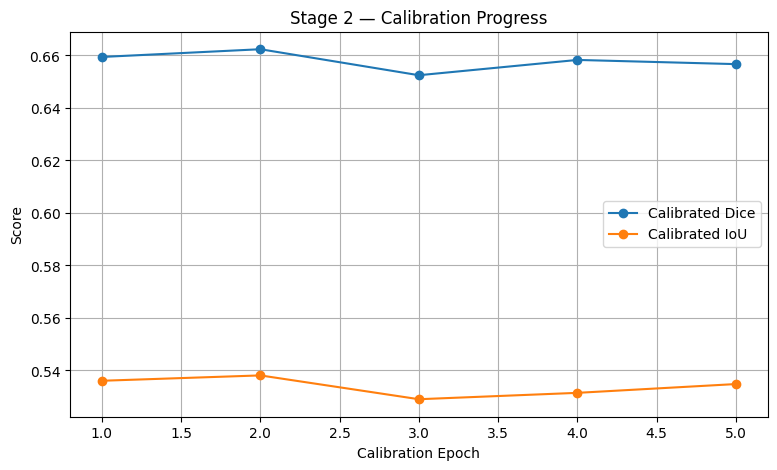

In [57]:
calibration_df = pd.DataFrame(
    calibration_history
)

display(calibration_df)

plt.figure(figsize=(9, 5))

plt.plot(
    calibration_df["epoch"],
    calibration_df["dice"],
    marker="o",
    label="Calibrated Dice"
)

plt.plot(
    calibration_df["epoch"],
    calibration_df["iou"],
    marker="o",
    label="Calibrated IoU"
)

plt.xlabel("Calibration Epoch")
plt.ylabel("Score")
plt.title("Stage 2 — Calibration Progress")
plt.legend()
plt.grid(True)

plt.show()

Auto Calibration Summary

In [58]:
best_row = calibration_df.loc[
    calibration_df["dice"].idxmax()
]

print("========== AUTO CALIBRATION RESULT ==========")

print("Best Epoch :", int(best_row["epoch"]))
print("Best Dice  :", round(best_row["dice"], 4))
print("Best IoU   :", round(best_row["iou"], 4))
print("Best Action:", best_row["action"])

print("\nFinal Class Weights:")

for name, weight in zip(
    CLASS_NAMES,
    calibration_weights
):
    print(
        f"{name:15s}: {weight.item():.4f}"
    )

========== AUTO CALIBRATION RESULT ==========
Best Epoch : 2
Best Dice  : 0.6624
Best IoU   : 0.5381
Best Action: SMALL_ADJUST

Final Class Weights:
Background     : 1.5568
Building       : 1.5568
Road           : 1.5568
Water          : 1.5568
Barren         : 1.7903
Forest         : 1.4790
Agriculture    : 1.5568


Load Best Calibrated Model

In [59]:
calibrated_model = smp.UnetPlusPlus(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=3,
    classes=NUM_CLASSES,
    activation=None
).to(DEVICE)

calibrated_model.load_state_dict(
    torch.load(
        "LoveDA_UNetPlusPlus_Calibrated_Best.pth",
        map_location=DEVICE
    )
)

calibrated_model.eval()

print("Best calibrated U-Net++ loaded.")

Best calibrated U-Net++ loaded.


Baseline vs Calibrated

In [60]:
# Stage 1 baseline
baseline_loss, baseline_dice, baseline_iou = validate(
    best_model,
    val_loader,
    criterion
)

# Stage 2 calibrated
calibrated_loss, calibrated_dice, calibrated_iou = validate(
    calibrated_model,
    val_loader,
    criterion
)

comparison = pd.DataFrame({
    "Model": [
        "Stage 1 — Normal U-Net++",
        "Stage 2 — Calibrated U-Net++"
    ],
    "Validation Loss": [
        baseline_loss,
        calibrated_loss
    ],
    "Dice": [
        baseline_dice,
        calibrated_dice
    ],
    "IoU": [
        baseline_iou,
        calibrated_iou
    ]
})

display(comparison)

,Model,Validation Loss,Dice,IoU
0,Stage 1 — Normal U-Net++,0.617508,0.637597,0.513509
1,Stage 2 — Calibrated U-Net++,0.655388,0.662369,0.538123


Comparison Graph 📊

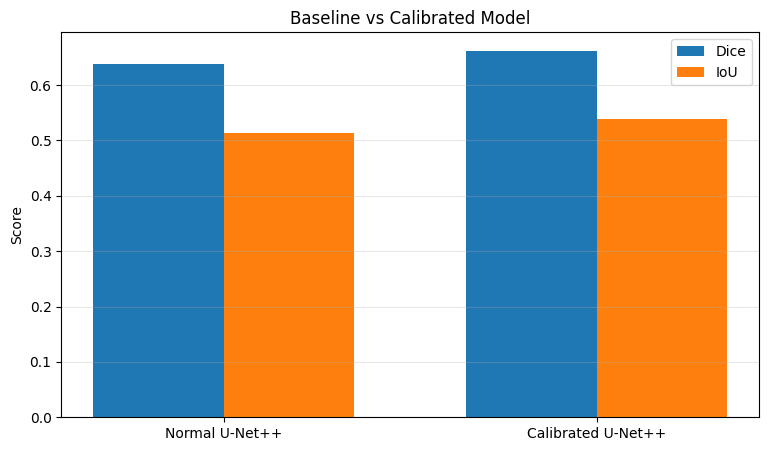

In [61]:
x = np.arange(2)
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width/2,
    comparison["Dice"],
    width,
    label="Dice"
)

plt.bar(
    x + width/2,
    comparison["IoU"],
    width,
    label="IoU"
)

plt.xticks(
    x,
    ["Normal U-Net++", "Calibrated U-Net++"]
)

plt.ylabel("Score")
plt.title("Baseline vs Calibrated Model")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

Final New Satellite Image

In [62]:
from google.colab import files

uploaded = files.upload()

NEW_IMAGE_PATH = next(
    iter(uploaded.keys())
)

print("Uploaded:", NEW_IMAGE_PATH)

Saving Media.jpg to Media (1).jpg
Uploaded: Media (1).jpg


Baseline vs Calibrated Prediction

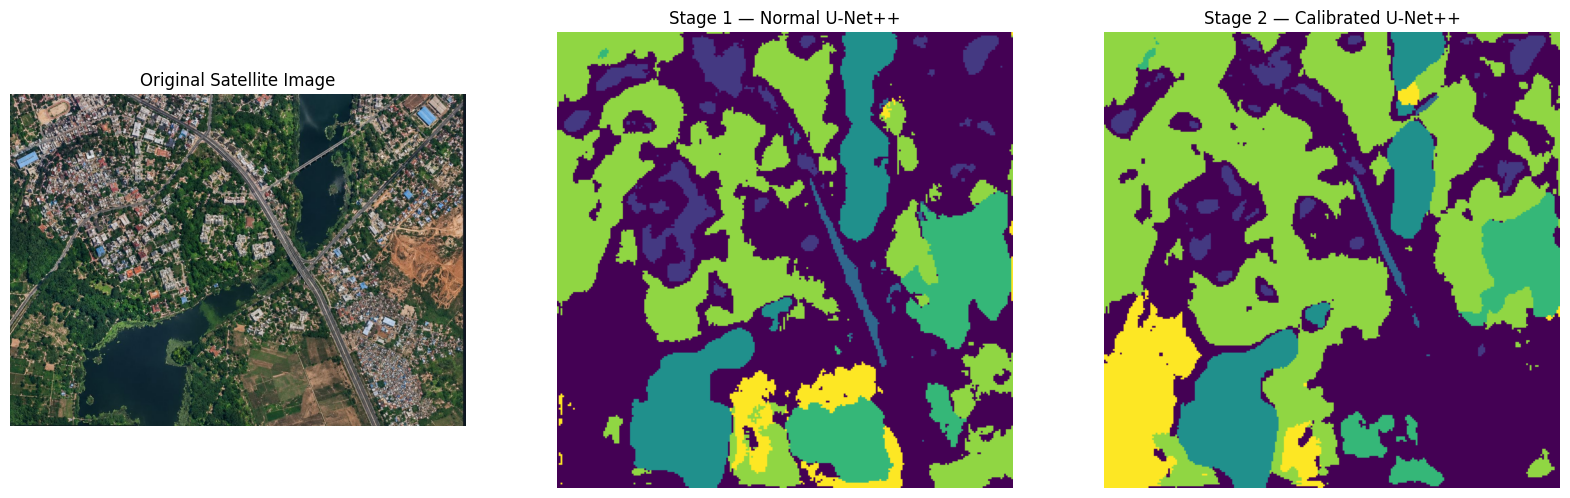

In [63]:
new_image = Image.open(
    NEW_IMAGE_PATH
).convert("RGB")

resized = new_image.resize(
    (IMAGE_SIZE, IMAGE_SIZE),
    Image.Resampling.BILINEAR
)

arr = np.asarray(
    resized
).astype(np.float32) / 255.0

new_tensor = torch.from_numpy(
    arr
).permute(2, 0, 1)

baseline_prediction = predict_tensor(
    best_model,
    new_tensor
)

calibrated_prediction = predict_tensor(
    calibrated_model,
    new_tensor
)

plt.figure(figsize=(20, 6))

plt.subplot(1, 3, 1)
plt.imshow(new_image)
plt.title("Original Satellite Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(
    baseline_prediction,
    vmin=0,
    vmax=NUM_CLASSES-1
)
plt.title("Stage 1 — Normal U-Net++")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(
    calibrated_prediction,
    vmin=0,
    vmax=NUM_CLASSES-1
)
plt.title("Stage 2 — Calibrated U-Net++")
plt.axis("off")

plt.show()